# VI and MCMC with iTARFlow

**Run this notebook:** in Colab, choose **Runtime → Run all**. The first cell prepares METIS automatically using uv; a fresh runtime needs this setup again. These short tutorials use a CPU. Locally, select your [METIS Python environment](https://ojwatson.github.io/metis/basics/installing_metis.html).

The outputs below were generated when the documentation was built. [Source revision `b20b270c079a`](https://github.com/OJWatson/metis/tree/b20b270c079ad27a227a41b67828abcde7c74f87).

In [ ]:
#@title Prepare METIS (run once per runtime)
"""Embedded in notebook downloads: prepare their disposable Colab runtime with uv."""

import importlib
import importlib.metadata
import importlib.util
import io
import json
import os
from pathlib import Path
import platform
import re
import shutil
import subprocess
import sys
import tarfile
import urllib.request


UV_VERSION = "0.7.22"
INSTALL_GUIDE = "https://ojwatson.github.io/metis/basics/installing_metis.html"


def _installed_version(package):
    try:
        return importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        return None


def _compatible_pin(package, minimum, maximum=None):
    """Preserve compatible binary libraries already supplied by Colab."""
    version = _installed_version(package)
    if version is None:
        return None
    match = re.match(r"^(\d+)\.(\d+)(?:\.(\d+))?", version)
    if match is None:
        return None
    release = tuple(int(value or 0) for value in match.groups())
    if release < minimum or (maximum is not None and release >= maximum):
        return None
    return f"{package}=={version}"


def _uv_executable(directory):
    installed = shutil.which("uv")
    if installed:
        return installed
    destination = directory / "uv"
    if not destination.exists():
        architecture = {"x86_64": "x86_64", "aarch64": "aarch64"}.get(platform.machine())
        if architecture is None:
            raise RuntimeError(f"Unsupported Colab CPU architecture: {platform.machine()}")
        archive_name = f"uv-{architecture}-unknown-linux-gnu"
        url = (
            f"https://github.com/astral-sh/uv/releases/download/{UV_VERSION}/"
            f"{archive_name}.tar.gz"
        )
        with urllib.request.urlopen(url, timeout=120) as response:
            archive_bytes = response.read()
        with tarfile.open(fileobj=io.BytesIO(archive_bytes), mode="r:gz") as archive:
            # Read one known member, without extracting arbitrary archive paths.
            binary = archive.extractfile(f"{archive_name}/uv")
            if binary is None:
                raise RuntimeError("The uv release archive contains no executable")
            destination.write_bytes(binary.read())
        destination.chmod(0o755)
    return str(destination)


def _project_text(revision):
    dependencies = [
        f"metis-surrogate[plots,pandas] @ git+https://github.com/OJWatson/metis.git@{revision}",
        "torch==2.10.0",
    ]
    for package, minimum, maximum in [
        ("numpy", (2, 0, 0), (3, 0, 0)),
        ("matplotlib", (3, 9, 0), (4, 0, 0)),
        ("pandas", (2, 2, 0), (4, 0, 0)),
        ("pyarrow", (18, 0, 0), None),
        ("polars", (1, 37, 0), (3, 0, 0)),
    ]:
        pin = _compatible_pin(package, minimum, maximum)
        if pin:
            dependencies.append(pin)
    return (
        '[project]\nname = "metis-colab-tutorial"\nversion = "0.0.0"\n'
        f'requires-python = ">={sys.version_info.major}.{sys.version_info.minor},'
        f'<{sys.version_info.major}.{sys.version_info.minor + 1}"\n'
        f"dependencies = {json.dumps(dependencies)}\n\n"
        '[tool.uv]\npackage = false\n\n'
        '[tool.uv.sources]\ntorch = { index = "pytorch-cpu" }\n\n'
        '[[tool.uv.index]]\nname = "pytorch-cpu"\n'
        'url = "https://download.pytorch.org/whl/cpu"\nexplicit = true\n'
    )


def _metis_origin():
    try:
        return importlib.metadata.distribution("metis-surrogate").read_text("direct_url.json")
    except importlib.metadata.PackageNotFoundError:
        return None


def prepare_colab(revision):
    """Install only inside Colab; local notebooks use the selected METIS environment."""
    if not re.fullmatch(r"[a-f0-9]{40}", revision):
        raise ValueError("Notebook setup needs an exact 40-character source revision")
    try:
        in_colab = (
            importlib.util.find_spec("google.colab") is not None
            and bool(os.environ.get("COLAB_RELEASE_TAG") or os.environ.get("COLAB_BACKEND_VERSION"))
        )
    except ModuleNotFoundError:
        in_colab = False
    if not in_colab:
        if _installed_version("metis-surrogate") is None:
            raise RuntimeError(f"Select a Python environment containing METIS: {INSTALL_GUIDE}")
        print(f"Using local METIS {_installed_version('metis-surrogate')}.")
        return
    if sys.version_info < (3, 11):
        raise RuntimeError("This tutorial requires a Colab runtime with Python 3.11 or newer.")

    directory = Path("/content/.metis-notebooks")
    directory.mkdir(parents=True, exist_ok=True)
    (directory / "pyproject.toml").write_text(_project_text(revision), encoding="utf-8")
    loaded = {
        package: str(getattr(sys.modules[package], "__version__", _installed_version(package)))
        for package in ("numpy", "pandas", "torch", "matplotlib", "pyarrow", "polars")
        if package in sys.modules
    }
    metis_was_loaded = "metis" in sys.modules
    previous_metis_origin = _metis_origin()
    if metis_was_loaded:
        # Retain the import's identity if the user reruns setup after a restart
        # warning without actually restarting the Python process.
        previous_metis_origin = sys.modules["metis"].__dict__.setdefault(
            "_notebook_runtime_origin", previous_metis_origin,
        )
    environment = os.environ.copy()
    # Colab is a disposable runtime. Keep its unrelated packages and its active
    # notebook interpreter, instead of adding a second environment to sys.path.
    environment["UV_PROJECT_ENVIRONMENT"] = sys.prefix
    environment.pop("VIRTUAL_ENV", None)
    print("Preparing this Colab runtime with uv (CPU tutorial environment)…")
    result = subprocess.run(
        [_uv_executable(directory), "sync", "--inexact", "--no-dev", "--no-editable",
         "--project", str(directory), "--python", sys.executable],
        env=environment, text=True, capture_output=True,
    )
    if result.returncode:
        raise RuntimeError(f"METIS setup failed:\n{result.stdout}\n{result.stderr}")
    importlib.invalidate_caches()
    changed = [package for package, before in loaded.items() if _installed_version(package) != before]
    if metis_was_loaded and _metis_origin() != previous_metis_origin:
        changed.append("metis")
    if changed:
        raise RuntimeError(
            "Setup updated already-loaded libraries (" + ", ".join(changed) + "). "
            "Choose Runtime > Restart session, then Run all. Setup will reuse its installed packages."
        )
    print(f"METIS {_installed_version('metis-surrogate')} is ready. Continue with the tutorial.")


prepare_colab("b20b270c079ad27a227a41b67828abcde7c74f87")


METIS's [normalising flow surrogate](https://ojwatson.github.io/metis/models/normalising-flow.html) has an
exactly evaluable density. This lets us substitute the fitted surrogate into
inference methods such as variational inference (VI) and Markov chain Monte
Carlo (MCMC).

Conceptually, the simulator has a likelihood $p^*(y\mid\theta)$ that we cannot
easily evaluate. We fit a surrogate density $\hat p(y\mid\theta)$ and hope it
approximates the features of that likelihood needed for inference. An exact
calculation of $\hat p$ does not make it the exact simulator likelihood.

## Setup

We continue with the same [SIRDS model](https://ojwatson.github.io/metis/basics/sirds-example.html), its four
count trajectories, and the bundled simulation bank. The following cells run
when the documentation is built; the optional VI and MCMC recipes later on
explain how a validated surrogate would enter an inference workflow.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from metis import load_example, Surrogate, TrainingConfig

bank = load_example()
split = bank.split(seed=42)
torch.manual_seed(42)

## Train the surrogate

As in the normalising-flow tutorial, we fit a small iTARFlow model on the SIRDS
training groups and select its weights using the validation groups.

In [2]:
nf = Surrogate(
    "itarflow",
    model_options={"channels": 32, "num_layers": 1, "num_blocks": 2, "num_heads": 2},
).fit(
    split.train, split.validation,
    config=TrainingConfig(steps=1000, batch_size=64, eval_every=100, seed=42),
)
nf.save("sirds-likelihood.pt")

PosixPath('sirds-likelihood.pt')

## Load the trained surrogate

The saved model includes its input and output names, time grid and fitted
scalers. Loading it does not require the training data or a reconstruction of
its preprocessing:

In [3]:
nf = Surrogate.load("sirds-likelihood.pt")
print("Inputs:", nf.input_names)
print("Outputs:", nf.output_names)

Inputs: ('I_0', 'beta', 'gamma', 'omega', 'mu')
Outputs: ('S_t', 'I_t', 'R_t', 'D_t')


## Preparing an observation

Use one trajectory from a held-out SIRDS parameter group as our observation.
For this illustration, select a group inside each training-input range. Its
generating parameters are known, so we can compare them with a likelihood
slice later. For a scientific application this would instead be the observed
data whose likelihood is being evaluated.

In [4]:
in_range = np.all(
    (split.test.inputs >= split.train.inputs.min(axis=0))
    & (split.test.inputs <= split.train.inputs.max(axis=0)), axis=1,
)
observation_index = np.flatnonzero(in_range)[0]
true_inputs = split.test.inputs[observation_index:observation_index + 1].copy()
y_obs = split.test.outputs[observation_index:observation_index + 1].copy()
same_setting = np.all(split.test.inputs == true_inputs[0], axis=1)
replicates = split.test.outputs[same_setting]
draws = nf.sample(true_inputs, n_samples=100, seed=13)[0]

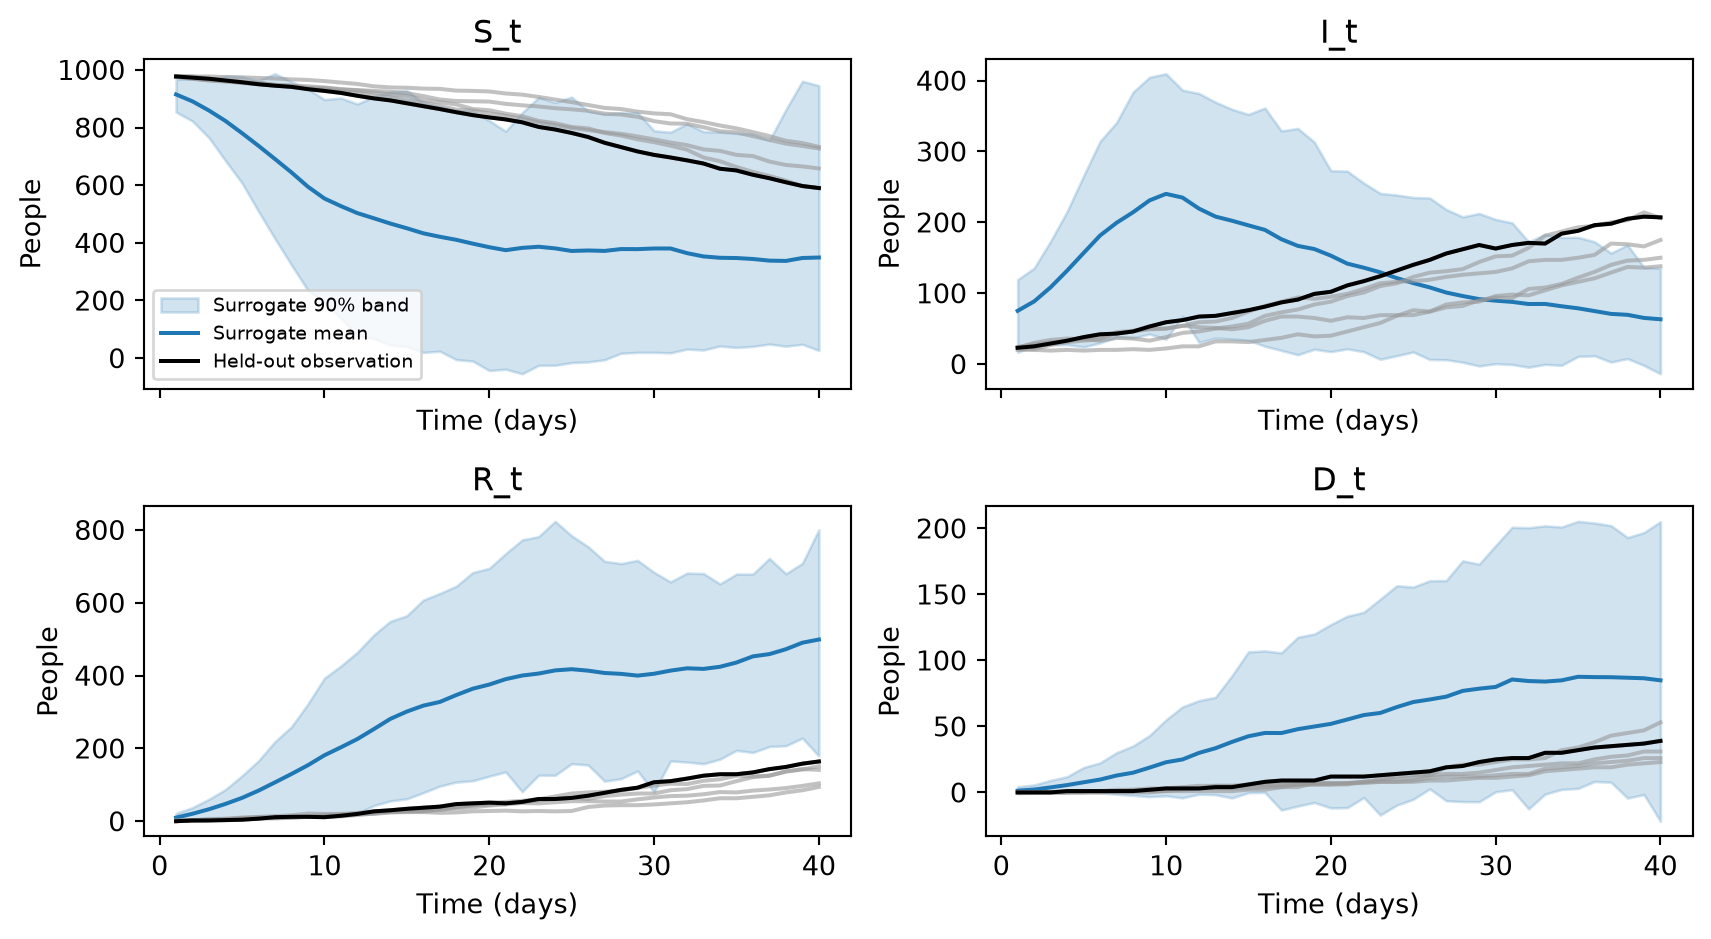

In [5]:
#| code-fold: true
#| code-summary: "Compare surrogate samples with held-out SIRDS trajectories"
#| fig-cap: "iTARFlow fitted to the bundled SIRDS training split: surrogate samples at one held-out parameter setting, compared with its five SIRDS realisations. Shading is the pointwise 5th–95th percentile of 100 surrogate draws, not a posterior interval."
low, high = np.quantile(draws, [0.05, 0.95], axis=0)
fig, axes = plt.subplots(2, 2, figsize=(9, 5), sharex=True)
for j, ax in enumerate(axes.flat):
    ax.fill_between(bank.times, low[:, j], high[:, j], alpha=0.2,
                    color="C0", label="Surrogate 90% band")
    ax.plot(bank.times, draws.mean(axis=0)[:, j], color="C0", label="Surrogate mean")
    ax.plot(bank.times, replicates[:, :, j].T, color="0.6", alpha=0.6)
    ax.plot(bank.times, y_obs[0, :, j], color="black", label="Held-out observation")
    ax.set(title=bank.output_names[j], xlabel="Time (days)", ylabel="People")
axes[0, 0].legend(fontsize=7)
fig.tight_layout()
plt.show()

*iTARFlow fitted to the bundled SIRDS training split: surrogate samples at one held-out parameter setting, compared with its five SIRDS realisations. Shading is the pointwise 5th–95th percentile of 100 surrogate draws, not a posterior interval.*

This short fit illustrates the interface. The plots reveal where its samples
miss the SIRDS trajectories; they do not establish that its likelihood is
adequate for parameter inference.

## Evaluating the likelihood

`log_prob` accepts inputs and trajectories in their original units. To inspect
its dependence on transmission rate, vary $\beta$ while holding the other four
inputs at their generating values:

In [6]:
beta_index = bank.input_names.index("beta")
beta = np.linspace(split.train.inputs[:, beta_index].min(),
                   split.train.inputs[:, beta_index].max(), 100)
candidates = np.repeat(true_inputs, len(beta), axis=0)
candidates[:, beta_index] = beta
log_density = nf.log_prob(candidates, np.repeat(y_obs, len(beta), axis=0))

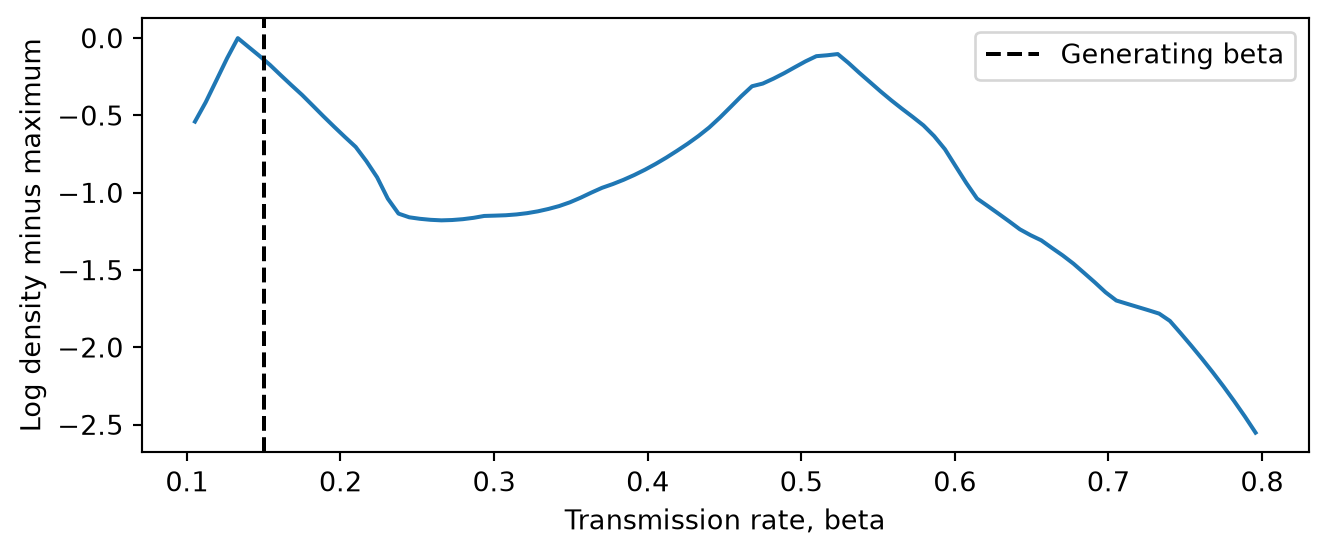

In [7]:
#| fig-cap: "iTARFlow fitted to the bundled SIRDS training split: conditional log-density slice for one held-out SIRDS trajectory, with I₀, γ, ω and μ fixed to their generating values. The curve is shifted to its maximum; it is not a marginal likelihood or posterior."
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(beta, log_density - log_density.max())
ax.axvline(true_inputs[0, beta_index], color="black", linestyle="--",
           label="Generating beta")
ax.set(xlabel="Transmission rate, beta", ylabel="Log density minus maximum")
ax.legend()
fig.tight_layout()
plt.show()

*iTARFlow fitted to the bundled SIRDS training split: conditional log-density slice for one held-out SIRDS trajectory, with I₀, γ, ω and μ fixed to their generating values. The curve is shifted to its maximum; it is not a marginal likelihood or posterior.*

For gradient-based methods, `log_prob_tensor` keeps the calculation connected
to PyTorch's automatic differentiation. Scaling and its density correction
are handled inside the package:

In [8]:
theta = torch.tensor(true_inputs, requires_grad=True)
observed = torch.tensor(y_obs)
log_likelihood = nf.log_prob_tensor(theta, observed)
gradient, = torch.autograd.grad(log_likelihood.sum(), theta)
print("Log density:", float(log_likelihood.detach()[0]))
print("Gradient in original input units:")
for name, value in zip(bank.input_names, gradient[0].tolist()):
    print(f"  {name}: {value:.3f}")

Log density: -703.8670975764833
Gradient in original input units:
  I_0: 87.204
  beta: -7.933
  gamma: -38.375
  omega: 17.625
  mu: -298.801


SIRDS has integer counts and a fixed population total. A continuous flow does
not enforce this support, and its density is not a discrete trajectory
probability. Before interpreting a posterior, validate an appropriate
likelihood or observation model, simulation coverage and inference diagnostics.
No observation-error model is added in this tutorial.

## Choosing the prior

For the **optional inference recipes** below, suppose we want to infer the
initial infected fraction $I_0$, transmission $\beta$, recovery $\gamma$ and
waning $\omega$, holding mortality $\mu$ known. The example uniform priors are:

$$
\begin{aligned}
I_0 &\sim \mathcal U(0.01, 0.1), &
\beta &\sim \mathcal U(0.2, 0.8),\\
\gamma &\sim \mathcal U(0.05, 0.3), &
\omega &\sim \mathcal U(0.005, 0.05).
\end{aligned}
$$

These are choices for the example, not priors selected by METIS. They must be
scientifically justified and covered by a validated simulation bank before
use. The small bundled bank and short fit above are not that validation.

## The inference problem

Given observation $y_{\mathrm{obs}}$, prior $p(\theta)$ and the fitted surrogate,
the unnormalised approximate posterior is

$$
p(\theta\mid y_{\mathrm{obs}})\propto
\hat p(y_{\mathrm{obs}}\mid\theta)\,p(\theta).
$$

VI fits a tractable distribution to this target; MCMC generates samples from
it. The following code is an **unexecuted advanced recipe**, rather than
reported inference results. It uses the same SIRDS observation and the public
likelihood interface demonstrated above.

```python
import torch.distributions as dist
from torch import nn

parameter_names = ["I_0", "beta", "gamma", "omega"]
lo = torch.tensor([0.01, 0.2, 0.05, 0.005])
hi = torch.tensor([0.1, 0.8, 0.3, 0.05])
known_mu = float(true_inputs[0, bank.input_names.index("mu")])

# Freeze fitted neural weights while preserving gradients through the inputs.
nf.model.requires_grad_(False)

def make_inputs(theta_samples):
    values = dict(zip(parameter_names, theta_samples.unbind(dim=1)))
    values["mu"] = torch.full_like(theta_samples[:, 0], known_mu)
    return torch.stack([values[name] for name in nf.input_names], dim=1)

def compute_log_likelihood(theta_samples):
    return nf.log_prob_tensor(
        make_inputs(theta_samples),
        observed.expand(len(theta_samples), -1, -1),
    )
```

## Variational inference

Introduce a parametrised distribution $q_\phi(\theta)$ and maximise the evidence
lower bound (ELBO):

$$
\max_\phi\;\mathbb E_{q_\phi}\left[
\log\hat p(y_{\mathrm{obs}}\mid\theta)+\log p(\theta)-\log q_\phi(\theta)
\right].
$$

This is equivalent to minimising the reverse KL divergence from $q_\phi$ to
the approximate posterior. As in the original workflow, use a multivariate
Gaussian transformed into the parameter bounds:

```python
import torch.nn.functional as F

n_params = len(parameter_names)
q_mu = nn.Parameter(torch.zeros(n_params))
q_L_flat = nn.Parameter(torch.zeros(n_params * (n_params + 1) // 2))

def build_q():
    L = torch.zeros(n_params, n_params)
    row, column = torch.tril_indices(n_params, n_params)
    L[row, column] = q_L_flat
    diagonal = torch.arange(n_params)
    L[diagonal, diagonal] = F.softplus(L[diagonal, diagonal])
    base = dist.MultivariateNormal(q_mu, scale_tril=L)
    return dist.TransformedDistribution(base, [
        dist.SigmoidTransform(), dist.AffineTransform(lo, hi - lo),
    ])

optimizer = torch.optim.Adam([q_mu, q_L_flat], lr=0.02)
elbo_history = []
for step in range(1500):
    optimizer.zero_grad()
    q = build_q()
    theta_samples = q.rsample((32,))
    log_prior = -torch.log(hi - lo).sum()
    elbo = (compute_log_likelihood(theta_samples)
            + log_prior - q.log_prob(theta_samples)).mean()
    (-elbo).backward()
    optimizer.step()
    elbo_history.append(float(elbo.detach()))

with torch.no_grad():
    vi_samples = build_q().sample((5000,)).numpy()

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(elbo_history)
ax.set(xlabel="VI step", ylabel="ELBO")
plt.show()
```

Check convergence from different initialisations. An improving ELBO alone does
not show that the approximation represents every posterior mode or correlation.

## MCMC

Pyro's No-U-Turn Sampler (NUTS) can sample the same surrogate-based target. Pyro
is optional; add it to your uv project before running this recipe:

```bash
uv add pyro-ppl
```

Each `pyro.sample` declares a prior, and `pyro.factor` contributes the surrogate
log likelihood. Pyro handles the transforms for bounded parameters.

```python
import pyro
import pyro.distributions as pyro_dist
from pyro.infer import MCMC, NUTS

pyro.set_rng_seed(42)

def posterior_model():
    theta = torch.stack([
        pyro.sample(name, pyro_dist.Uniform(lo[i], hi[i]))
        for i, name in enumerate(parameter_names)
    ])
    pyro.factor("surrogate_likelihood", compute_log_likelihood(theta[None])[0])

kernel = NUTS(posterior_model, full_mass=True, target_accept_prob=0.8)
mcmc = MCMC(kernel, warmup_steps=500, num_samples=1000, num_chains=1)
mcmc.run()
mcmc.summary(prob=0.95)
mcmc_draws = mcmc.get_samples()
mcmc_samples = torch.stack([mcmc_draws[name] for name in parameter_names], dim=1)
```

Warmup adapts the sampler and is discarded. This notebook-style recipe shows
one chain; scientific inference needs independently initialised chains, mixing
and effective-sample-size checks, divergence checks and between-chain
convergence diagnostics.

### Comparing VI and MCMC

Plot both sets of marginal samples, then examine joint parameter relationships
and trace plots. Agreement between the methods does not establish that the
surrogate likelihood itself is accurate.

```python
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for j, ax in enumerate(axes):
    ax.hist(vi_samples[:, j], bins=30, density=True, histtype="step", label="VI")
    ax.hist(mcmc_samples[:, j].numpy(), bins=30, density=True,
            histtype="step", label="MCMC")
    generating = true_inputs[0, bank.input_names.index(parameter_names[j])]
    ax.axvline(generating, color="black", linestyle="--", label="Generating value")
    ax.set(xlabel=parameter_names[j], ylabel="Density")
axes[0].legend()
fig.tight_layout()
plt.show()
```

### Posterior predictive checks

Generate SIRDS surrogate trajectories at posterior parameter draws and compare
with the observed trajectory. Do not clip negative counts or enforce
conservation after sampling: those discrepancies help reveal a poor surrogate.

```python
selected = mcmc_samples[:100]
posterior_inputs = make_inputs(selected).detach().numpy()
posterior_predictive = nf.sample(posterior_inputs, n_samples=1, seed=42)[:, 0]

fig, axes = plt.subplots(2, 2, figsize=(9, 5), sharex=True)
for j, ax in enumerate(axes.flat):
    ax.plot(bank.times, posterior_predictive[:, :, j].T, color="C0", alpha=0.1)
    ax.plot(bank.times, y_obs[0, :, j], color="black", label="Observation")
    ax.set(title=bank.output_names[j], xlabel="Time (days)", ylabel="People")
axes[0, 0].legend()
fig.tight_layout()
plt.show()
```

These posterior samples would describe parameter uncertainty under the chosen
prior and fitted surrogate. They do not include uncertainty in the fitted
neural weights. For SIRDS, a further check is to run the actual simulator at
posterior draws and compare those trajectories with the observation.